# Red neuronal funcional: entrenamiento 1981–1997 y prueba 1998–2003, sin estaciones compartidas
Validación cruzada de 5 folds agrupados por estación dentro del entrenamiento. La partición se genera en R y se verifica nuevamente en Python.


In [1]:
import sys
sys.path.append('funciones')
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display
from Entrenamiento_red import *


## Comprobaciones de la cabeza MLP
Dimensiones, gradientes y semillas reproducibles para cada q y M, sin entrenamiento.

In [2]:
datos, W, R, cov_norm, opciones_q, opciones_m = main_cabeza_mlp()

q=6, M=4, ocultas=8: cabeza MLP=108 parámetros; 3 semillas correctas
q=6, M=5, ocultas=8: cabeza MLP=117 parámetros; 3 semillas correctas
q=6, M=6, ocultas=8: cabeza MLP=126 parámetros; 3 semillas correctas
q=7, M=4, ocultas=8: cabeza MLP=116 parámetros; 3 semillas correctas
q=7, M=5, ocultas=8: cabeza MLP=125 parámetros; 3 semillas correctas
q=7, M=6, ocultas=8: cabeza MLP=134 parámetros; 3 semillas correctas
q=8, M=4, ocultas=8: cabeza MLP=124 parámetros; 3 semillas correctas
q=8, M=5, ocultas=8: cabeza MLP=133 parámetros; 3 semillas correctas
q=8, M=6, ocultas=8: cabeza MLP=142 parámetros; 3 semillas correctas
Comprobaciones finalizadas. No se entrenó ni se generaron archivos.


## KAN: resolución de la malla

In [3]:
# Resolución de la malla para el seno de la función sintética
torch.set_num_threads(1)
x_malla = torch.linspace(-1, 1, 1001, dtype=torch.float64)
x_intermedia = (x_malla[:-1] + x_malla[1:]) / 2
resolucion = []
for intervalos in (4, 8, 12, 16):
    capa = CapaKAN(1, 1, intervalos)
    coeficientes = torch.linalg.lstsq(capa.bases(x_malla), torch.sin(2 * torch.pi * x_malla)).solution
    error = capa.bases(x_intermedia) @ coeficientes - torch.sin(2 * torch.pi * x_intermedia)
    resolucion.append({'intervalos': intervalos, 'RMSE_aproximacion': error.square().mean().sqrt().item()})
tabla_resolucion = pd.DataFrame(resolucion)
print(tabla_resolucion.to_string(index=False))
# Doce intervalos reducen el error de aproximación del seno a cerca de 0,00115

 intervalos  RMSE_aproximacion
          4           0.242062
          8           0.008393
         12           0.001151
         16           0.000312


## KAN: comprobación con una función sintética
La KAN debe aproximar la función sintética con RMSE ≤ 0,01 antes de usar datos reales.

In [4]:
# Comprobación sintética con ajuste, validación y verificación independientes
generador = torch.Generator().manual_seed(2026)
x_sintetica = 4 * torch.rand(2200, 8, generator=generador, dtype=torch.float64) - 2
funcion = torch.sin(torch.pi * x_sintetica[:, 0]) + x_sintetica[:, 1].square()
escalas_salida = torch.tensor([[0.5, 0.75, 1.0, 1.25]], dtype=torch.float64)
y_sintetica = funcion[:, None] * escalas_salida
x_ajuste, x_validacion, x_verificacion = x_sintetica[:1400], x_sintetica[1400:1800], x_sintetica[1800:]
y_ajuste, y_validacion, y_verificacion = y_sintetica[:1400], y_sintetica[1400:1800], y_sintetica[1800:]
resultados_sinteticos = []
for semilla in SEMILLAS:
    establecer_semilla(semilla)
    cabeza = CabezaKAN(neuronas=6, m_fpca=4)
    cabeza.calibrar(x_ajuste)
    optimizador = torch.optim.AdamW(cabeza.parameters(), lr=0.01, weight_decay=0)
    mejor_validacion = float('inf')
    sin_mejora = 0
    for epoca in range(1, 4001):
        cabeza.train()
        optimizador.zero_grad(set_to_none=True)
        perdida = (cabeza(x_ajuste) - y_ajuste).square().mean()
        perdida.backward()
        optimizador.step()
        cabeza.eval()
        with torch.no_grad():
            perdida_validacion = (cabeza(x_validacion) - y_validacion).square().mean().item()
        if perdida_validacion < mejor_validacion - 1e-10:
            mejor_validacion = perdida_validacion
            mejor_estado = {nombre: valor.detach().clone() for nombre, valor in cabeza.state_dict().items()}
            mejor_epoca = epoca
            sin_mejora = 0
        else:
            sin_mejora += 1
        if sin_mejora >= 300:
            break
    cabeza.load_state_dict(mejor_estado)
    with torch.no_grad():
        error_verificacion = cabeza(x_verificacion) - y_verificacion
        rmse_salida = error_verificacion.square().mean(dim=0).sqrt()
        rmse = error_verificacion.square().mean().sqrt().item()
    resultados_sinteticos.append({
        'semilla': semilla, 'mejor_epoca': mejor_epoca,
        'RMSE_validacion': np.sqrt(mejor_validacion), 'RMSE_verificacion': rmse,
        'RMSE_max_salida': rmse_salida.max().item(),
    })
    print(f'KAN sintética, semilla {semilla:04d}, RMSE de verificación = {rmse:.6f}')
    if semilla == SEMILLAS[0]:
        cabeza_sintetica = cabeza
tabla_sintetica = pd.DataFrame(resultados_sinteticos)
print(tabla_sintetica.to_string(index=False))
print(tabla_sintetica[['RMSE_verificacion', 'RMSE_max_salida']].agg(['mean', 'std']).to_string())
assert np.isfinite(tabla_sintetica['RMSE_max_salida']).all()
assert tabla_sintetica['RMSE_max_salida'].le(0.01).all(), 'La KAN supera el RMSE sintético permitido.'
tabla_sintetica.to_csv('Tablas/06_KAN_sintetica.csv', index=False)
# Las tres semillas quedan por debajo de 0,01 en cada una de las cuatro salidas sintéticas

KAN sintética, semilla 0001, RMSE de verificación = 0.001117
KAN sintética, semilla 0002, RMSE de verificación = 0.001117
KAN sintética, semilla 0003, RMSE de verificación = 0.001117
 semilla  mejor_epoca  RMSE_validacion  RMSE_verificacion  RMSE_max_salida
       1         3982         0.001104           0.001117         0.001521
       2         3999         0.001104           0.001117         0.001521
       3         3995         0.001104           0.001117         0.001521
      RMSE_verificacion  RMSE_max_salida
mean       1.117151e-03     1.521218e-03
std        6.026773e-08     1.805232e-07


## KAN: activaciones de la capa de entrada

In [5]:
# Activaciones de la capa de entrada en el rango del ajuste sintético
primera_capa = cabeza_sintetica.capas[0]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for entrada, ax in enumerate(axes):
    rejilla = torch.linspace(x_ajuste[:, entrada].min(), x_ajuste[:, entrada].max(), 200, dtype=torch.float64)
    for salida in range(primera_capa.salidas):
        valores = primera_capa.arista(salida, entrada, rejilla)
        ax.plot(rejilla.numpy(), (valores - valores.mean()).numpy(), label=f'Arista hacia la salida {salida + 1}')
    ax.set_title(f'x{entrada + 1}')
    ax.legend(fontsize=8)
plt.suptitle('Capa de entrada de la KAN · función sintética · semilla 0001')
plt.tight_layout()
fig.savefig('Figuras/06_KAN_activaciones_sinteticas.png', dpi=150)
plt.close(fig)

## KAN: ajuste simbólico

In [6]:
# Ajuste simbólico de la arista de x2 hacia la primera salida de la capa
rejilla = torch.linspace(x_ajuste[:, 1].min(), x_ajuste[:, 1].max(), 200, dtype=torch.float64)
coef_simbolicos, _, r2_simbolico = ajustar_simbolica(primera_capa, 0, 1, rejilla)
tabla_simbolica = pd.DataFrame([{
    'semilla': SEMILLAS[0], 'entrada': 1, 'salida': 0,
    'centro': primera_capa.centro[1].item(), 'escala': primera_capa.escala[1].item(),
    'a0': coef_simbolicos[0].item(), 'a1': coef_simbolicos[1].item(),
    'a2': coef_simbolicos[2].item(), 'a3': coef_simbolicos[3].item(),
    'R2_verificacion': r2_simbolico,
}])
print('Expresión de la arista sintética: a0 + a1*u + a2*u² + a3*u³, u = (x-centro)/escala')
print(tabla_simbolica.to_string(index=False))
tabla_simbolica.to_csv('Tablas/06_KAN_simbolica_sintetica.csv', index=False)

Expresión de la arista sintética: a0 + a1*u + a2*u² + a3*u³, u = (x-centro)/escala
 semilla  entrada  salida   centro   escala        a0       a1      a2       a3  R2_verificacion
       1        1       0 0.003881 1.993801 -0.721783 0.007873 1.98773 -0.00017              1.0


## Integración del codificador y la KAN
Parámetros de KAN y MLP igualados (diferencia ≤ 10 %).

In [7]:
# Partición temporal: entrenamiento 1981-1997; prueba 1998-2003
anios = np.asarray(datos['YEAR'])
particiones = np.asarray(datos['particion'])
idx_entrenamiento = particiones == 'entrenamiento'
idx_prueba = particiones == 'prueba'
assert np.all((anios >= 1981) & (anios <= 2003))
assert np.all(particiones == np.where(anios <= 1997, 'entrenamiento', 'prueba'))
assert idx_entrenamiento.any() and idx_prueba.any()
assert not np.any(idx_entrenamiento & idx_prueba)
assert 'STATION_ID' in datos, 'Falta STATION_ID; vuelve a exportar desde R y actualiza el módulo.'
ids_train = set(np.asarray(datos['STATION_ID'])[idx_entrenamiento].astype(str))
ids_test = set(np.asarray(datos['STATION_ID'])[idx_prueba].astype(str))
assert not (ids_train & ids_test), 'Hay estaciones repetidas entre entrenamiento y prueba.'
assert len(ids_train) >= 5 and len(ids_test) > 0, 'No hay suficientes estaciones para 5 folds y prueba.'
print(f'Entrenamiento (1981-1997): {idx_entrenamiento.sum()} curvas')
print(f'Prueba (1998-2003): {idx_prueba.sum()} curvas')
print('Validación cruzada: 5 folds por estación, solo con entrenamiento')
# Preparar entradas para la KAN
# Solo se utilizan datos de entrenamiento
c_entrenamiento = torch.as_tensor(datos['c'][idx_entrenamiento], dtype=torch.float64)
cov_entrenamiento = torch.as_tensor(cov_norm[idx_entrenamiento], dtype=torch.float64)

# Comprobaciones del codificador y la KAN
comprobaciones = []
parametros_cabezas = []
for q in opciones_q:
    for m in opciones_m:
        for semilla in SEMILLAS:
            establecer_semilla(semilla)
            modelo = ModeloCodificadorCabezaKAN(W, R, q, m)
            with torch.no_grad():
                h_entrenamiento = modelo.codificador(c_entrenamiento, cov_entrenamiento)
                modelo.cabeza.calibrar(h_entrenamiento)
            c_lote = c_entrenamiento[:16]
            cov_lote = cov_entrenamiento[:16]
            coordenadas = modelo(c_lote, cov_lote)
            coordenadas.square().mean().backward()
            gradientes = all(
                p.grad is not None
                and torch.isfinite(p.grad).all().item()
                and p.grad.abs().sum().item() > 0
                for p in modelo.parameters()
            )
            establecer_semilla(semilla)
            replica = ModeloCodificadorCabezaKAN(W, R, q, m)
            with torch.no_grad():
                replica.cabeza.calibrar(replica.codificador(c_entrenamiento, cov_entrenamiento))
                error_replica = (coordenadas - replica(c_lote, cov_lote)).abs().max().item()
            comprobaciones.append({
                'q': q,
                'M': m,
                'semilla': semilla,
                'dimensiones_correctas': coordenadas.shape == (len(c_lote), m),
                'salida_finita': torch.isfinite(coordenadas).all().item(),
                'gradientes_finitos_no_nulos': gradientes,
                'error_replica': error_replica,
            })

        # Comparación de parámetros KAN y MLP
        n_kan = contar_parametros(modelo.cabeza)
        ocultas_mlp = max(1, round((n_kan - m) / (q + m + 3)))
        n_mlp = contar_parametros(CabezaMLP(q, m, ocultas_mlp))
        parametros_cabezas.append({
            'q': q,
            'M': m,
            'ocultas_KAN': OCULTAS_KAN,
            'intervalos': INTERVALOS_KAN,
            'grado': 3,
            'parametros_KAN': n_kan,
            'ocultas_MLP': ocultas_mlp,
            'parametros_MLP': n_mlp,
            'diferencia_pct': 100 * abs(n_mlp - n_kan) / n_kan,
            'parametros_codificador': contar_parametros(modelo.codificador),
        })

# Verificación de resultados
tabla_comprobaciones = pd.DataFrame(comprobaciones)
print(tabla_comprobaciones.to_string(index=False))
assert tabla_comprobaciones[['dimensiones_correctas', 'salida_finita', 'gradientes_finitos_no_nulos']].all().all()
assert tabla_comprobaciones['error_replica'].eq(0).all()
# El gradiente alcanza el codificador y las dos capas KAN
# con inicializaciones reproducibles
tabla_comprobaciones.to_csv('Tablas/06_KAN_comprobaciones.csv', index=False)

tabla_parametros = pd.DataFrame(parametros_cabezas)
print(tabla_parametros.to_string(index=False))
assert tabla_parametros['diferencia_pct'].le(10).all()
tabla_parametros.to_csv('Tablas/06_KAN_parametros.csv', index=False)
print('La KAN devuelve M coordenadas latentes.')

Entrenamiento (1981-1997): 1958 curvas
Prueba (1998-2003): 127 curvas
Validación cruzada: 5 folds por estación, solo con entrenamiento
 q  M  semilla  dimensiones_correctas  salida_finita  gradientes_finitos_no_nulos  error_replica
 6  4        1                   True           True                         True            0.0
 6  4        2                   True           True                         True            0.0
 6  4        3                   True           True                         True            0.0
 6  5        1                   True           True                         True            0.0
 6  5        2                   True           True                         True            0.0
 6  5        3                   True           True                         True            0.0
 6  6        1                   True           True                         True            0.0
 6  6        2                   True           True                         True        

## Entrenamiento de la red funcional
Se comparan las cabezas lineal, MLP y KAN con validación cruzada agrupada por estación. En cada fold las estaciones de ajuste y validación son distintas. Las estaciones de prueba (1998–2003) no aparecen en ninguno de los folds.


In [8]:
# Búsqueda por validación cruzada de 5 folds y ajuste final
if ESCALA is not None:
    resultados = main_entrenamiento(ESCALA, n_folds=5)


Grupo 1: 189 entrenamientos
Grupo 2: 189 entrenamientos
Grupo 3: 189 entrenamientos
Grupo 4: 189 entrenamientos
Grupo 5: 189 entrenamientos
        q  M  lambda        mean        std  epocas_finales
cabeza                                                     
KAN     8  5    10.0   78.808905  13.219659              91
MLP     8  5   100.0   83.420390  13.174369             700
lineal  8  5    10.0  104.390003  26.712045            2756
 semilla  diferencia_max_integral  diferencia_max_coeficientes
       1             3.996803e-14                 9.325873e-15
       2             3.597123e-14                 1.021405e-14
       3             3.774758e-14                 1.199041e-14


## Resultados
### Parámetros de las cabezas

In [9]:
pd.read_csv('Tablas/08_red_parametros_cabezas.csv')

,q,M,parametros_lineal,parametros_KAN,ocultas_MLP,parametros_MLP,diferencia_pct
0,6,5,45,680,48,677,0.441176
1,7,5,50,765,51,770,0.653595
2,8,5,55,850,53,853,0.352941


### Varianza explicada de la FPCA

,M,varianza_explicada_acumulada
0,1,0.648973
1,2,0.781192
2,3,0.860243
3,4,0.915036
4,5,0.960117
5,6,1.000000


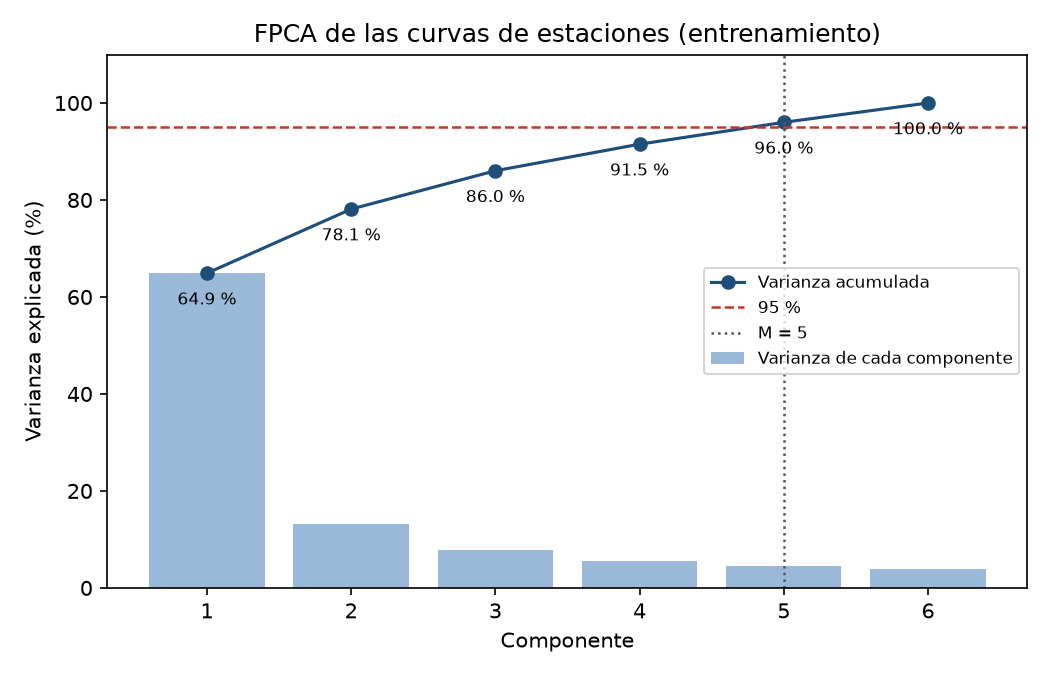

In [10]:
display(pd.read_csv('Tablas/08_red_fpca_varianza.csv'))
display(Image('Figuras/08_red_fpca_sedimentacion.png', width=650))

### Configuración elegida por validación cruzada
Pérdida L² funcional promedio de los cinco folds (tres semillas), calculada solamente con curvas de entrenamiento.

In [11]:
pd.read_csv('Tablas/08_red_configuracion_elegida.csv')

,cabeza,q,M,lambda,mean,std,epocas_finales
0,KAN,8,5,10.0,78.808905,13.219659,91
1,MLP,8,5,100.0,83.420390,13.174369,700
2,lineal,8,5,10.0,104.390003,26.712045,2756


In [12]:
pd.read_csv('Tablas/08_red_equivalencia_lineal.csv')

,semilla,diferencia_max_integral,diferencia_max_coeficientes
0,1,3.996803e-14,9.325873e-15
1,2,3.597123e-14,1.021405e-14
2,3,3.774758e-14,1.199041e-14


### Valores recortados en 0 al reconstruir las predicciones (entrenamiento, ajuste final)

In [13]:
pd.read_csv('Tablas/08_red_valores_recortados.csv')

,cabeza,semilla,valores_recortados_pct
0,lineal,1,0.000283
1,lineal,2,0.000213
2,lineal,3,0.004533
3,MLP,1,0.010696
4,MLP,2,0.000000
5,MLP,3,0.034709
6,KAN,1,0.008784
7,KAN,2,0.012821
8,KAN,3,0.008500


### Pérdida L² de validación cruzada por cabeza, q y λ (M = 5)

In [14]:
busqueda = pd.read_csv('Tablas/08_red_busqueda_hiperparametros.csv')
print('Folds:', sorted(busqueda.fold.unique()))
display(busqueda.groupby(['cabeza', 'q', 'lambda'])['perdida_validacion'].agg(['mean', 'std']).unstack('lambda').round(3))


Folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


mean                                                        \
lambda   0.01     0.10     1.00     10.00    100.00   1000.00  10000.00   
cabeza q                                                                  
KAN    6   79.710   79.752   79.601   79.501   79.138   78.659   79.578   
       7   79.688   79.731   79.770   79.611   79.728   78.800   79.462   
       8   78.892   78.864   78.933   78.809   79.083   80.099   79.875   
MLP    6   83.642   83.997   84.669   83.849   82.813   82.202   83.347   
       7   87.066   86.531   86.509   90.894   90.701   93.258   94.619   
       8   85.772   83.947   87.170   85.069   83.420   88.539   90.055   
lineal 6  109.493  109.494  109.443  109.398  109.153  109.782  112.281   
       7  107.570  107.643  107.687  107.617  107.658  107.945  111.542   
       8  104.502  104.494  104.536  104.390  104.545  105.976  111.421   

              std                                                        
lambda   0.01     0.10     1.00     10.00    100.00   1000.00  10000.00  
cabeza q                                                                 
KAN    6   12.786   12.829   12.845   12.838   12.944   12.393   11.849  
       7   12.694   12.805   12.839   12.798   12.588   12.431   11.855  
       8   13.111   13.118   12.954   13.220   12.907   12.934   12.439  
MLP    6   12.119   12.888   13.167   11.988   11.402   12.029   11.350  
       7   13.861   15.374   15.643   16.813   15.870   25.336   25.081  
       8   15.185   14.395   17.247   13.260   13.174   15.299   17.525  
lineal 6   26.625   26.576   26.532   26.505   26.353   26.916   28.781  
       7   25.881   25.857   25.797   25.849   25.939   27.390   28.305  
       8   26.637   26.714   26.677   26.712   26.544   26.990   27.857

### Historial del reajuste final con todo el entrenamiento
Después de elegir los parámetros por validación cruzada, cada cabeza se reajusta con 1981–1997. La cantidad de épocas se fija usando la mediana de las mejores épocas de los folds; los datos de prueba no intervienen en la parada ni en la selección.

lineal semilla=0001: 2756 épocas
lineal semilla=0002: 2756 épocas
lineal semilla=0003: 2756 épocas
MLP semilla=0001: 700 épocas
MLP semilla=0002: 700 épocas
MLP semilla=0003: 700 épocas
KAN semilla=0001: 91 épocas
KAN semilla=0002: 91 épocas
KAN semilla=0003: 91 épocas


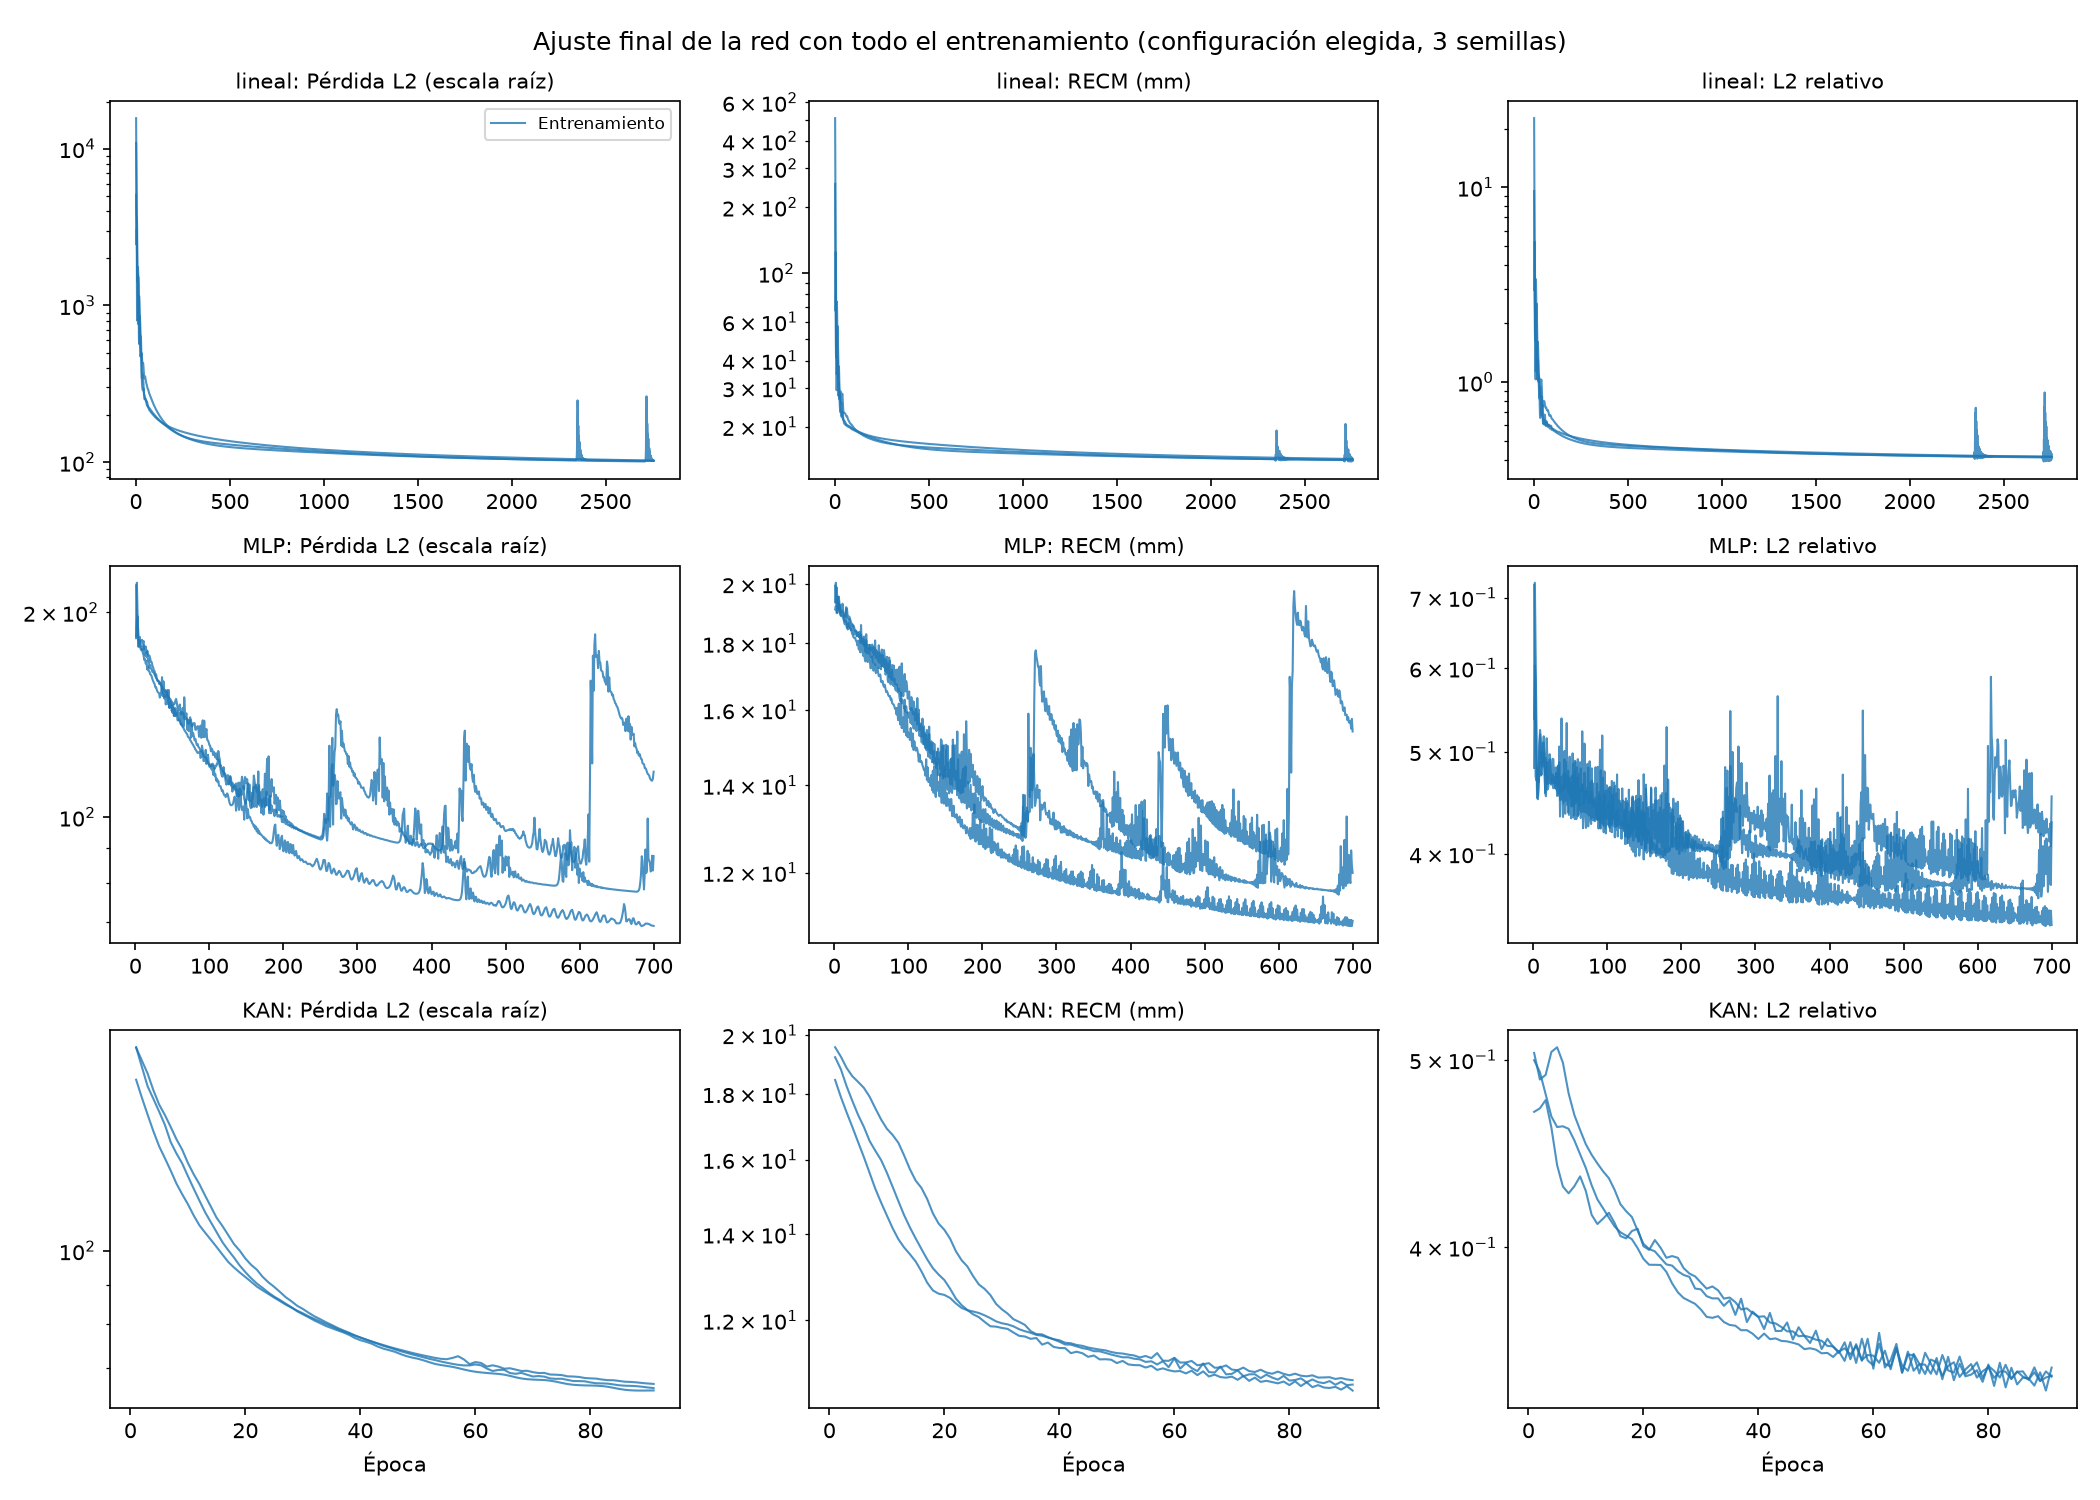

In [15]:
historial = historial_entrenamiento(ESCALA)
grafica_historial(historial, 'Figuras/08_red_curvas_entrenamiento.png')
display(Image('Figuras/08_red_curvas_entrenamiento.png', width=1000))

In [16]:
# Métricas del reajuste final (solo entrenamiento; tres semillas)
guardada = historial[historial.epoca == historial.mejor_epoca]
display(guardada.groupby('cabeza')[['mejor_epoca', 'L2_entrenamiento', 'RECM_entrenamiento', 'L2_relativo_entrenamiento']].mean().round(3))


,mejor_epoca,L2_entrenamiento,RECM_entrenamiento,L2_relativo_entrenamiento
cabeza,,,,
KAN,91.0,65.989,10.687,0.344
MLP,700.0,91.126,12.804,0.408
lineal,2756.0,102.225,14.120,0.418
